# Step 6: Diagnostics and Error Analysis

**BT4222 Final Project, Group 13, JDSearch**

Step 6 explains the numbers of Steps 4 and 5 instead of just reporting them: **who** the models serve well (history length), **what** they rank well (items the training histories contain versus unseen items), **how sure** we can be of a difference (paired bootstrap) and **how much the temporal features are worth** (a matched ablation).

## How to read this notebook

Every code cell is cut verbatim from `src/step6_diagnostics.py`, so the notebook and the script cannot drift apart
(`tests/test_notebooks.py` checks it). Each cell is preceded by a short explanation of what it does and
why, and the table below links every section to the function that implements it and to the file it
produces, so any number in the report can be traced back to a cell.

* **Part A** rebuilds the step. It needs the inputs listed below.
* **Part B** reads the measured outputs of the corrected run (`artifacts/corrected`) and re-checks them.
  It needs no raw data, so it always runs and its outputs are saved in this copy of the notebook.

| Section | What it does | Code in `src/step6_diagnostics.py` | Writes |
|---|---|---|---|
| A.1 | Settings, ablation feature list | `TEMPORAL_FEATURES` | - |
| A.2 | Rank of every positive in the full slate | `positive_rank_records` | - |
| A.3 | Paired bootstrap of a score difference | `bootstrap_difference` | - |
| A.4 | Load predictions, check identical populations | `main()` | - |
| A.5 | Segments, seen vs unseen items, rank by outcome | `main()` | `segment_metrics.csv`, `positive_subgroup_full_slate.csv`, `rank_by_type.csv` |
| A.6 | Paired bootstrap between models | `main()` | `paired_bootstrap.json` |
| A.7 | Matched temporal-feature ablation | `main()` | `ablation.json` |
| A.8 | Protocol notes | `main()` | `diagnostic_protocol.json` |
| B.1 | Is DHAR better than its controls? | - | - |
| B.2 | Who is served well? (history length) | - | - |
| B.3 | What is ranked well? (seen vs unseen items) | - | - |
| B.4 | Rank by outcome type, and the temporal ablation | - | - |

**Inputs.** `features.parquet`, `history.parquet`, `sessions.parquet`, `test_pred_lgb.parquet` (Step 4) and `test_pred_neural.parquet` (Step 5).

**Outputs.** `segment_metrics.csv`, `positive_subgroup_full_slate.csv`, `rank_by_type.csv`, `paired_bootstrap.json`, `ablation.json`, `diagnostic_protocol.json`.

## 0. Environment setup

The first cell finds the project and puts `src/` on `sys.path`, so `config`, `data_utils`
and `eval_utils` can be imported exactly as the scripts do.

* **In Colab** it clones the repository (branch set in `BRANCH`). Set `MOUNT_DRIVE = True` if the
  raw files live on Google Drive: raw paths and the output folder then point to Drive, so the
  outputs of one step survive until the next notebook.
* **Locally** it looks for `Final Project/` next to the notebook.
* All paths come from environment variables read by `src/config.py`:
  `JD_USER_TXT`, `JD_PRODUCT_TXT` (raw files), `JD_RUN_DIR` (where outputs are written, default
  `artifacts/corrected`), `JD_SEED` (default 42).

In [1]:
# Optional: install dependencies in a fresh environment (Colab already has most of them)
# !pip -q install numpy pandas pyarrow scipy scikit-learn lightgbm joblib matplotlib torch

import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/steffanylars/nus-web-mining-business-insights.git"
BRANCH = "main"   # final submission branch
MOUNT_DRIVE = False                    # Colab only: True keeps raw data and outputs on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/JDsearch"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if MOUNT_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        os.environ.setdefault("JD_USER_TXT", f"{DRIVE_DIR}/user_behavior_data.txt")
        os.environ.setdefault("JD_PRODUCT_TXT", f"{DRIVE_DIR}/product_meta_data.txt")
        os.environ.setdefault("JD_RUN_DIR", f"{DRIVE_DIR}/runs/corrected")
    repo = Path("/content/nus-web-mining-business-insights")
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(repo)], check=True)
    PROJECT_ROOT = repo / "Final Project"
else:
    here = Path.cwd()
    options = [here, here.parent, here / "Final Project", here.parent / "Final Project"]
    PROJECT_ROOT = next((p for p in options if (p / "src" / "config.py").exists()), None)
    assert PROJECT_ROOT is not None, "open this notebook from Final Project/ or Final Project/notebooks/"

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
print("in Colab    :", IN_COLAB)
print("project root:", PROJECT_ROOT)
print("run dir     :", os.environ.get("JD_RUN_DIR", "<default: artifacts/corrected>"))

in Colab    : False
project root: Final Project
run dir     : <default: artifacts/corrected>


## 1. Imports and shared helpers

`ranked_order` gives the same deterministic order used in scoring; `per_query` returns the metrics of
each query (needed for paired comparisons); `fit_ranker` and `LGB_PARAMS` come from Step 4 so the
ablation retrains with the identical recipe.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from config import OUT, RES, SEED, feature_columns, prepare, save_json
from eval_utils import evaluate, ranked_order, per_query
from step4_baselines_lgbm import fit_ranker, LGB_PARAMS

%matplotlib inline
prepare()

### 1.1 What can run here? (the `RUN_STEP` switch)

Part A rebuilds this step and Part B reads the measured outputs, so the switch below decides whether
Part A runs.

* Part A runs only if its **inputs exist**, and it will not overwrite the committed evidence in
  `artifacts/corrected` unless you explicitly allow it (`ALLOW_OVERWRITE`). In Colab the clone is
  disposable, so overwriting is allowed by default; locally, point `JD_RUN_DIR` at a new folder.
* If Part A is skipped, nothing fails: **Part B always runs** and shows the saved results.

In [3]:
COMMITTED = (PROJECT_ROOT / "artifacts" / "corrected").resolve()
ALLOW_OVERWRITE = IN_COLAB      # a Colab clone is disposable; locally keep the committed evidence safe
HAS_INPUTS = all((OUT / f).exists() for f in ["features.parquet", "history.parquet", "sessions.parquet", "test_pred_lgb.parquet", "test_pred_neural.parquet"])
RUN_STEP = HAS_INPUTS and (RES.resolve() != COMMITTED or ALLOW_OVERWRITE)

print("inputs found    :", HAS_INPUTS)
print("outputs go to   :", RES)
print("RUN_STEP        :", RUN_STEP)
if not RUN_STEP:
    why = ("required inputs not found: features, history, sessions, test_pred_lgb and test_pred_neural parquet files (run Steps 2 to 5 first)" if not HAS_INPUTS else
           "outputs would overwrite artifacts/corrected; set JD_RUN_DIR to a new folder or ALLOW_OVERWRITE = True")
    print("Part A is skipped here (" + why + ").")
    print("Part B below shows the measured outputs saved in", RES)

inputs found    : False
outputs go to   : Final Project/artifacts/corrected
RUN_STEP        : False
Part A is skipped here (required inputs not found: features, history, sessions, test_pred_lgb and test_pred_neural parquet files (run Steps 2 to 5 first)).
Part B below shows the measured outputs saved in Final Project/artifacts/corrected


# Part A: Run the diagnostics

### A.1 The temporal feature bundle (ablation list)

The 11 features that describe *when* and *what kind of* action happened: decayed affinities, horizon
hits, the age of the latest event and the counts of recent events, orders, carts and clicks. Removing
them together (A.7) measures what the Step 1 finding is worth.

`SKIP_FEATURE_ABLATION = True` skips the retraining of A.7 (it takes a few minutes).

In [4]:
TEMPORAL_FEATURES=['aff_cat_decay','aff_brand_decay','short_cat_hit','short_brand_hit',
    'long_cat_hit','long_brand_hit','h_min_elapsed','h_n_recent7','h_n_ord','h_n_cart','h_n_click']

SKIP_FEATURE_ABLATION = False

### A.2 Where does every positive land in the full slate?

Rank **all** candidates of a query first, then read the rank of each positive item. This avoids the
common mistake of ranking only a subset. For every positive the function records whether the item
appears in the complete training histories (`training_history_seen`) and whether it appears as a
training candidate (`training_candidate_seen`).

In [5]:
def positive_rank_records(pred,score,history_seen,training_candidates):
    records=[]
    for sid,g in pred.groupby('session_id',sort=True):
        order=ranked_order(g,score); ranks=np.empty(len(g),dtype=int)
        ranks[order]=np.arange(1,len(g)+1)
        for w,lab,rk in zip(g.cand_wid,g.label,ranks):
            if lab>0:
                records.append(dict(session_id=int(sid),cand_wid=w,label=int(lab),rank=int(rk),
                    training_history_seen=w in history_seen,
                    training_candidate_seen=w in training_candidates))
    return pd.DataFrame(records)

### A.3 Paired bootstrap of a difference

Two models are scored on the **same** queries, the per-query NDCG@10 differences are resampled 2,000
times, and the 2.5% and 97.5% quantiles of the mean difference form the 95% interval. A function that
raises if the two models do not cover identical queries keeps the comparison honest. The interval
reflects query sampling for fixed trained models, not the randomness of training.

In [6]:
def bootstrap_difference(first,second,score_first,score_second,repetitions=2000):
    a=per_query(first,score_first).set_index('session_id')['NDCG@10']
    b=per_query(second,score_second).set_index('session_id')['NDCG@10']
    if set(a.index)!=set(b.index):
        raise ValueError('Paired comparison requires identical evaluable queries')
    delta=b.sort_index().to_numpy()-a.sort_index().to_numpy()
    rng=np.random.default_rng(SEED)
    boot=[rng.choice(delta,len(delta),replace=True).mean() for _ in range(repetitions)]
    return dict(delta=float(delta.mean()),ci95=np.quantile(boot,[.025,.975]).tolist(),
        positive_queries=len(delta),resamples=repetitions,seed=SEED,
        interpretation='conditional on fixed saved models; not training-seed uncertainty')

### A.4 Load predictions and check that populations match

The LambdaMART and neural prediction files must contain exactly the same (session, candidate) pairs and
labels; otherwise any comparison would be between different test sets.

In [7]:
if RUN_STEP:
    feat=pd.read_parquet(OUT/'features.parquet')
    sess=pd.read_parquet(OUT/'sessions.parquet')
    hist=pd.read_parquet(OUT/'history.parquet')
    lp=pd.read_parquet(OUT/'test_pred_lgb.parquet')
    npred=pd.read_parquet(OUT/'test_pred_neural.parquet')
    keys=['session_id','cand_wid']
    merged=lp[keys+['label']].merge(npred[keys+['label']],on=keys,validate='one_to_one',suffixes=('_a','_b'))
    if len(merged)!=len(lp) or len(merged)!=len(npred) or not (merged.label_a==merged.label_b).all():
        raise ValueError('Prediction populations differ')
    train_ids=set(sess.loc[sess.split.eq('train'),'session_id'])
    history_seen=set(hist.loc[hist.session_id.isin(train_ids),'wid'])
    candidate_seen=set(feat.loc[feat.split.eq('train'),'cand_wid'])

### A.5 Segments, seen versus unseen items, rank by outcome

For LambdaMART and every neural variant:

* **history-length segments** (0 to 2, 3 to 20, 21 to 100, more than 100 events): NDCG@10 and the other
  metrics per segment;
* **seen versus unseen positives**: for positives whose item is (not) in the training histories, the
  share ranked in the top 10 and the mean and median rank in the full slate;
* **rank by outcome**: mean and median rank of clicked, carted and purchased items.

In [8]:
if RUN_STEP:
    models=[('LambdaMART',lp,'lgb_score')]
    models.extend((c.removesuffix('_score'),npred,c) for c in npred if c.endswith('_score'))
    segments=[]; rank_tables=[]; recalls=[]
    history_bins=pd.cut(sess.n_hist,[-1,2,20,100,np.inf],
        labels=['limited(0-2)','short(3-20)','medium(21-100)','long(>100)'])
    history_map=dict(zip(sess.session_id,history_bins.astype(str)))

In [9]:
if RUN_STEP:
    for name,pred,col in models:
        frame=pred.copy(); frame['history_group']=frame.session_id.map(history_map)
        for group,g in frame.groupby('history_group',sort=True):
            m,n=evaluate(g,col)
            segments.append(dict(model=name,history_group=group,positive_queries=n,
                all_queries=int(g.session_id.nunique()),**m))
        rr=positive_rank_records(pred,col,history_seen,candidate_seen)
        rr['model']=name; rank_tables.append(rr)
        for dimension in ['training_history_seen','training_candidate_seen']:
            for seen,g in rr.groupby(dimension):
                by_query=g.groupby('session_id')['rank'].apply(lambda x:float((x<=10).mean()))
                recalls.append(dict(model=name,dimension=dimension,seen=bool(seen),
                    positive_items=len(g),queries_with_subgroup_positive=len(by_query),
                    macro_recall10=float(by_query.mean()),micro_recall10=float(g['rank'].le(10).mean()),
                    mean_full_slate_rank=float(g['rank'].mean()),median_full_slate_rank=float(g['rank'].median())))
    pd.DataFrame(segments).to_csv(RES/'segment_metrics.csv',index=False)
    pd.DataFrame(recalls).to_csv(RES/'positive_subgroup_full_slate.csv',index=False)
    allr=pd.concat(rank_tables,ignore_index=True)
    allr.groupby(['model','label'])['rank'].agg(['mean','median','count']).to_csv(RES/'rank_by_type.csv')

### A.6 Paired bootstrap between models

DHAR minus LambdaMART, DHAR minus the MLP control (same features, no towers) and DHAR minus the pooled
history control.

In [10]:
if RUN_STEP:
    if 'dual_score' in npred:
        save_json(RES/'paired_bootstrap.json',dict(
            dual_minus_lgb=bootstrap_difference(lp,npred,'lgb_score','dual_score'),
            dual_minus_mlp=bootstrap_difference(npred,npred,'mlp_score','dual_score'),
            dual_minus_pooled=bootstrap_difference(npred,npred,'pooled_score','dual_score')))

### A.7 Matched temporal-feature ablation

Retrain LambdaMART **with the same recipe** (`fit_ranker`, same parameters) on all features except the
11 temporal ones, and compare it with the full LambdaMART from Step 4 on the same test slates. This
isolates the value of the feature bundle; it is not an ablation of the DHAR towers.

In [11]:
if RUN_STEP:
    if not SKIP_FEATURE_ABLATION:
        # Full arm is the headline model, not an unrelated retraining configuration.
        cols=feature_columns(feat)
        booster=fit_ranker(feat,[c for c in cols if c not in TEMPORAL_FEATURES])
        test=feat[feat.split.eq('test')].copy()
        test['score']=booster.predict(test[[c for c in cols if c not in TEMPORAL_FEATURES]])
        full=evaluate(lp,'lgb_score')[0]; without=evaluate(test,'score')[0]
        save_json(RES/'ablation.json',dict(full=full,no_temporal=without,
            delta_NDCG10=full['NDCG@10']-without['NDCG@10'],removed_features=TEMPORAL_FEATURES,
            params=LGB_PARAMS,interpretation='temporal/action feature bundle, not a DHAR tower ablation'))

### A.8 Protocol notes

A short machine-readable statement of how the diagnostics were defined, saved next to the results.

In [12]:
if RUN_STEP:
    save_json(RES/'diagnostic_protocol.json',dict(
        subgroup_ranks='rank every candidate first; measure positive subgroup ranks/recall in original full slate',
        history_seen='present in complete training histories',
        candidate_seen='present in training candidate rows, regardless of label',
        low_history='limited history, not proof of a new user',
        no_zero_history_claim='no natural zero-history benchmark is claimed'))
    print('Full-slate diagnostics and feature ablation complete',flush=True)

# Part B: Measured outputs of the corrected run

### B.1 Is DHAR better than its controls?

The saved intervals are recomputed here from the saved predictions with the same function and seed.
Matching the saved file proves that the quoted differences come from the quoted predictions.

In [13]:
lp = pd.read_parquet(OUT / "test_pred_lgb.parquet")
npred = pd.read_parquet(OUT / "test_pred_neural.parquet")
saved = json.loads((RES / "paired_bootstrap.json").read_text(encoding="utf-8"))
recomputed = dict(
    dual_minus_lgb=bootstrap_difference(lp, npred, "lgb_score", "dual_score"),
    dual_minus_mlp=bootstrap_difference(npred, npred, "mlp_score", "dual_score"),
    dual_minus_pooled=bootstrap_difference(npred, npred, "pooled_score", "dual_score"))
rows = []
for key, value in recomputed.items():
    rows.append(dict(comparison=key, delta=value["delta"], ci_low=value["ci95"][0], ci_high=value["ci95"][1],
                     saved_delta=saved[key]["delta"], abs_diff=abs(value["delta"] - saved[key]["delta"]),
                     interval_excludes_zero=not (value["ci95"][0] <= 0 <= value["ci95"][1])))
boot = pd.DataFrame(rows).set_index("comparison")
display(boot.round(5))
assert boot.abs_diff.max() < 1e-9, "recomputed bootstrap differs from the saved file"

,delta,ci_low,ci_high,saved_delta,abs_diff,interval_excludes_zero
comparison,,,,,,
dual_minus_lgb,0.00829,0.00219,0.01446,0.00829,0.0,True
dual_minus_mlp,-0.00116,-0.00336,0.00109,-0.00116,0.0,False
dual_minus_pooled,-0.00251,-0.00477,-0.00034,-0.00251,0.0,True


**Reading.** DHAR beats LambdaMART by +0.008 (interval above zero), but that gain comes from the neural
model and the **same features**, not from the towers: against the MLP control with no towers the
difference is -0.001 with an interval that contains zero, and against the pooled-history control it is
-0.003 (interval just below zero). The attention mechanism adds nothing measurable; this is reported as
an honest negative result.

### B.2 Who is served well? History length

history_group,limited(0-2),short(3-20),medium(21-100),long(>100)
model,,,,
LambdaMART,0.3450,0.3816,0.3537,0.3648
dual,0.3834,0.3919,0.3606,0.3720
history_cf,0.2079,0.2864,0.2571,0.2765
mlp,0.3807,0.3918,0.3609,0.3746
order_only,0.3689,0.3954,0.3618,0.3744
pooled,0.3867,0.3954,0.3619,0.3752
short_only,0.3756,0.3927,0.3596,0.3731


positive test queries per segment: {'limited(0-2)': 63, 'short(3-20)': 494, 'medium(21-100)': 1115, 'long(>100)': 1293}


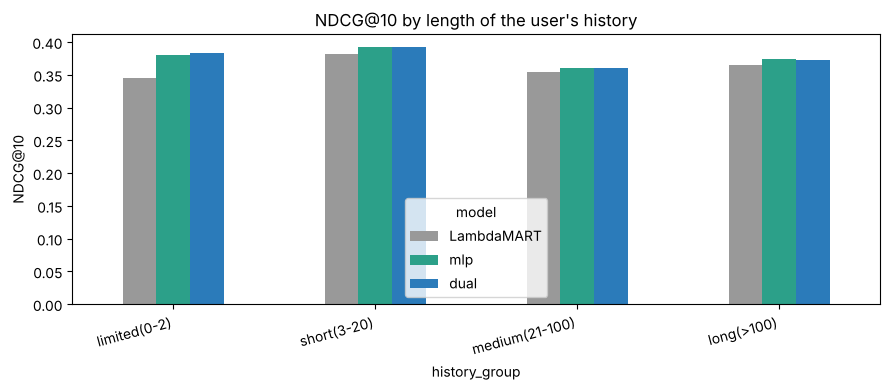

In [14]:
segments = pd.read_csv(RES / "segment_metrics.csv")
order = ["limited(0-2)", "short(3-20)", "medium(21-100)", "long(>100)"]
pivot = segments.pivot(index="model", columns="history_group", values="NDCG@10")[order]
counts = segments[segments.model == "LambdaMART"].set_index("history_group").positive_queries[order]
display(pivot.round(4))
print("positive test queries per segment:", counts.to_dict())

fig, ax = plt.subplots(figsize=(9, 4))
pivot.loc[["LambdaMART", "mlp", "dual"]].T.plot(kind="bar", ax=ax, color=["#999999", "#2ca089", "#2b7bba"])
ax.set(ylabel="NDCG@10", title="NDCG@10 by length of the user's history")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

**Reading.** No model collapses on short histories. The neural models score about 0.38 in the 0 to 2 events
group against 0.345 for LambdaMART, but that segment has only 63 positive queries, so the gap is noisy.

### B.3 What is ranked well? Items the training histories contain versus unseen items

The share of positive items placed in the top 10 of the **full** slate, split by whether the item appears
in any training history.

In [15]:
subgroup = pd.read_csv(RES / "positive_subgroup_full_slate.csv")
seen = subgroup[subgroup.dimension == "training_history_seen"]
view = seen[seen.model.isin(["LambdaMART", "mlp", "dual"])][
    ["model", "seen", "positive_items", "macro_recall10", "median_full_slate_rank"]]
display(view.round(3).reset_index(drop=True))

,model,seen,positive_items,macro_recall10,median_full_slate_rank
0,LambdaMART,False,3046,0.193,42.0
1,LambdaMART,True,2551,0.811,4.0
2,mlp,False,3046,0.227,41.0
3,mlp,True,2551,0.790,4.0
4,dual,False,3046,0.225,42.0
5,dual,True,2551,0.789,4.0


**Reading.** Positives that never appear in a training history reach the top 10 far less often than
positives the histories contain (LambdaMART: 19% versus 81%; DHAR: 23% versus 79%), and their median rank
in the full slate is about 42 instead of 4. The ceiling of this task is therefore on the **item side**: most candidates are unseen products, so
metadata and content features, not more user modelling, are the lever. Step 7 tests the user-side alternative
and confirms it does not help.

### B.4 Rank by outcome type and the temporal ablation

In [16]:
rank_by_type = pd.read_csv(RES / "rank_by_type.csv")
display(rank_by_type[rank_by_type.model.isin(["LambdaMART", "mlp", "dual"])]
        .pivot(index="model", columns="label", values="median").rename(columns={1: "click", 2: "cart", 3: "purchase"})
        .rename_axis(columns="median full-slate rank"))

ablation = json.loads((RES / "ablation.json").read_text(encoding="utf-8"))
print("LambdaMART NDCG@10, all features      :", round(ablation["full"]["NDCG@10"], 4))
print("LambdaMART NDCG@10, no temporal bundle:", round(ablation["no_temporal"]["NDCG@10"], 4))
print("value of the temporal bundle          :", round(ablation["delta_NDCG10"], 4))
print("removed features:", ablation["removed_features"])
print("note:", ablation["interpretation"])

median full-slate rank,click,cart,purchase
model,,,
LambdaMART,18.0,10.0,5.0
dual,18.0,10.0,5.0
mlp,18.0,10.0,5.0


LambdaMART NDCG@10, all features      : 0.363
LambdaMART NDCG@10, no temporal bundle: 0.3387
value of the temporal bundle          : 0.0243
removed features: ['aff_cat_decay', 'aff_brand_decay', 'short_cat_hit', 'short_brand_hit', 'long_cat_hit', 'long_brand_hit', 'h_min_elapsed', 'h_n_recent7', 'h_n_ord', 'h_n_cart', 'h_n_click']
note: temporal/action feature bundle, not a DHAR tower ablation


# Summary

* **Temporal features are the solid contribution**: removing the 11-feature bundle costs 0.024 NDCG@10
  in a matched LambdaMART ablation.
* **DHAR's attention towers add nothing** over the same features without towers (difference -0.001,
  interval contains zero).
* **The limit is the item side**: unseen positives are far harder to rank than seen ones.
* Purchases are ranked highest, then carts, then clicks (median rank by outcome), consistent with the
  purchase-weighted gains.

**Hand-off to Step 7:** the segment and subgroup tables motivate testing a user-side cold-start fix.